# 36 · Trajectory generation: cubic, quintic, min-jerk, trapezoid; joint vs Cartesian paths

In [1]:
import mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt
from vlacourse import add_ee_site, solve_ik, yaw_quat

def cubic(T, n=200):
    t = np.linspace(0, T, n); u = t / T
    return t, 3 * u**2 - 2 * u**3, (6 * u - 6 * u**2) / T, (6 - 12 * u) / T**2

def quintic(T, n=200):
    t = np.linspace(0, T, n); u = t / T
    return t, 10 * u**3 - 15 * u**4 + 6 * u**5, (30 * u**2 - 60 * u**3 + 30 * u**4) / T, (60 * u - 180 * u**2 + 120 * u**3) / T**2

def trapezoid(T, n=200, ramp=0.25):
    t = np.linspace(0, T, n); vmax = 1 / (T * (1 - ramp))
    ta = ramp * T
    s = np.where(t < ta, 0.5 * vmax / ta * t**2, np.where(t < T - ta, vmax * (t - ta / 2), 1 - 0.5 * vmax / ta * (T - t) ** 2))
    v = np.gradient(s, t); a = np.gradient(v, t)
    return t, s, v, a

def panda():
    spec = mm.get("franka_emika_panda").spec("panda"); add_ee_site(spec)
    m = spec.compile(); d = mujoco.MjData(m)
    d.qpos[:7] = [0, 0, 0, -1.571, 0, 1.571, -0.785]; mujoco.mj_forward(m, d)
    return m, d

def ee_path(model, data, qs):
    out = []
    for q in qs:
        data.qpos[:7] = q; mujoco.mj_kinematics(model, data); out.append(data.site("ee").xpos.copy())
    return np.array(out)

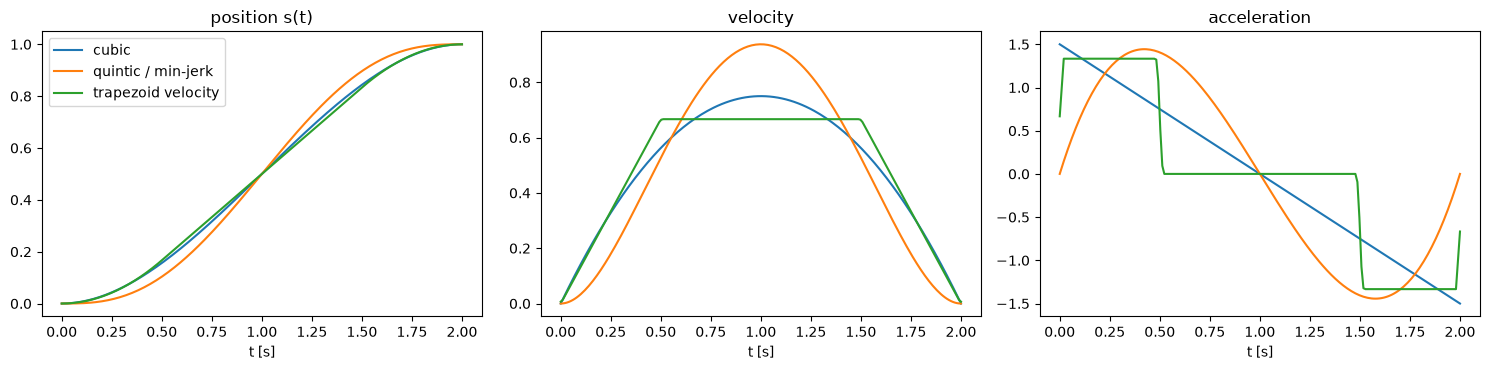

cubic: acceleration jumps at t=0 and t=T (infinite jerk). quintic: zero velocity AND acceleration at both ends.


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for name, f in [("cubic", cubic), ("quintic / min-jerk", quintic), ("trapezoid velocity", trapezoid)]:
    t, s, v, a = f(2.0)
    axes[0].plot(t, s, label=name); axes[1].plot(t, v); axes[2].plot(t, a)
for ax, lab in zip(axes, ["position s(t)", "velocity", "acceleration"]):
    ax.set_title(lab); ax.set_xlabel("t [s]")
axes[0].legend(); plt.tight_layout(); plt.show()
print("cubic: acceleration jumps at t=0 and t=T (infinite jerk). quintic: zero velocity AND acceleration at both ends.")

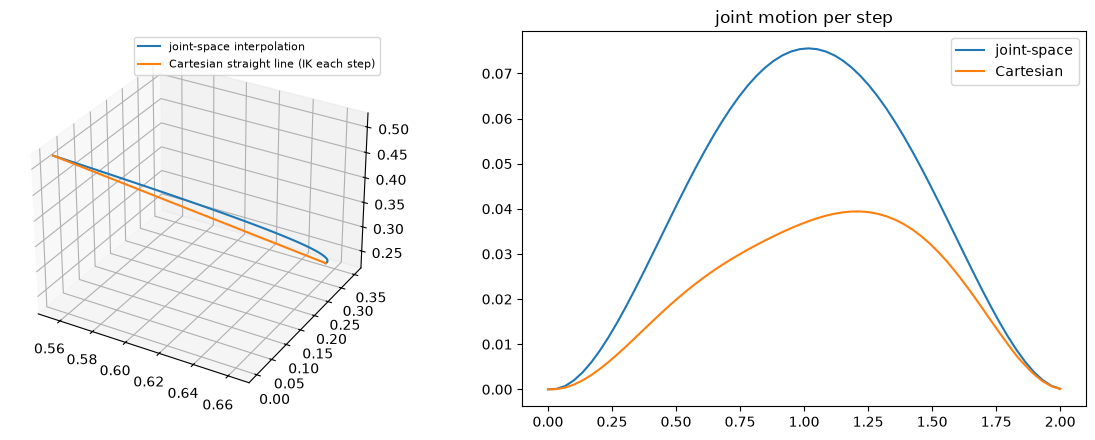

max deviation of the joint-space path from the straight line: 4.8 cm


In [3]:
model, data = panda()
p0 = data.site("ee").xpos.copy(); p1 = p0 + np.array([0.1, 0.35, -0.3])
q0 = data.qpos[:7].copy()
q1, _ = solve_ik(model, data, p1, yaw_quat(0.0), q0)
t, s, _, _ = quintic(2.0, 60)
joint_interp = q0 + np.outer(s, q1 - q0)
cart_interp = []
q = q0
for si in s:
    q, _ = solve_ik(model, data, p0 + si * (p1 - p0), yaw_quat(0.0), q, iters=60)
    cart_interp.append(q)
P_joint, P_cart = ee_path(model, data, joint_interp), ee_path(model, data, np.array(cart_interp))
fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot(*P_joint.T, label="joint-space interpolation"); ax.plot(*P_cart.T, label="Cartesian straight line (IK each step)"); ax.legend(fontsize=8)
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(t, np.linalg.norm(np.diff(joint_interp, axis=0, prepend=joint_interp[:1]), axis=1), label="joint-space")
ax2.plot(t, np.linalg.norm(np.diff(np.array(cart_interp), axis=0, prepend=np.array(cart_interp)[:1]), axis=1), label="Cartesian")
ax2.set_title("joint motion per step"); ax2.legend(); plt.tight_layout(); plt.show()
print(f"max deviation of the joint-space path from the straight line: {np.max(np.linalg.norm(np.cross(P_joint - p0, (p1 - p0) / np.linalg.norm(p1 - p0)), axis=1)) * 100:.1f} cm")

In [4]:
vmax = np.array([2.17, 2.17, 2.17, 2.17, 2.61, 2.61, 2.61])
dq = np.abs(q1 - q0)
for T in [0.5, 1.0, 2.0]:
    peak = 1.875 * dq / T
    print(f"T={T}s quintic peak joint speed / limit: {np.max(peak / vmax):.2f}  {'OK' if np.all(peak < vmax) else 'VIOLATES limits'}")
T_min = np.max(1.875 * dq / vmax)
print(f"minimum feasible duration for this move: {T_min:.3f} s (time scaling by the slowest joint)")

T=0.5s quintic peak joint speed / limit: 3.10  VIOLATES limits
T=1.0s quintic peak joint speed / limit: 1.55  VIOLATES limits
T=2.0s quintic peak joint speed / limit: 0.77  OK
minimum feasible duration for this move: 1.548 s (time scaling by the slowest joint)
